# E-Commerce Medallion Architecture (Bronze → Silver → Gold) + SCD Type 2 (PySpark)
Deze notebook volgt de vereisten uit de assignment: Bronze (as-is) → Silver (clean/standardize) → Gold (star schema) met **SCD Type 2** voor customers/sellers en **MERGE (upsert)** voor Gold.

**Aanbevolen omgeving:** Google Colab + Google Drive.

## Dataset files (verwacht)
- orders_dataset.csv
- order_items_dataset.csv
- products_dataset.csv
- product_category_name_translation.csv
- sellers_dataset.csv
- (optioneel/aanbevolen) customers_dataset.csv, order_payments_dataset.csv, order_reviews_dataset.csv, geolocation_dataset.csv

> Als je niet alle bestanden hebt, zal de notebook de ontbrekende delen overslaan waar mogelijk.

In [1]:
# 0) Install & Spark session (Colab)
!pip install pyspark -q
!pip install delta-spark -q

from pyspark.sql import SparkSession, functions as F, Window
import os, glob, re

from delta import configure_spark_with_delta_pip

builder = (
    SparkSession.builder
    .appName("ECommerce_Medallion_SCD2")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()
spark.conf.set("spark.sql.session.timeZone", "UTC")

spark


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 1.4 MB/s eta 0:00:00


In [2]:
# 1) Storage setup (Google Drive)
# In Colab: zet je CSV's in RAW folder op Drive.

from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/medallion_ecommerce"
RAW = f"{BASE}/raw"
BRONZE = f"{BASE}/bronze"
SILVER = f"{BASE}/silver"
GOLD = f"{BASE}/gold"

for p in [RAW, BRONZE, SILVER, GOLD]:
    os.makedirs(p, exist_ok=True)

print("Folders ready:", RAW, BRONZE, SILVER, GOLD)


Mounted at /content/drive
Folders ready: /content/drive/MyDrive/medallion_ecommerce/raw /content/drive/MyDrive/medallion_ecommerce/bronze /content/drive/MyDrive/medallion_ecommerce/silver /content/drive/MyDrive/medallion_ecommerce/gold


### Optioneel: als je in Colab werkt en je CSV's lokaal uploadt
Dan kan je ze kopiëren naar `RAW`. (In Drive is beter.)

In [3]:
# (Optioneel) Copy uploaded files to RAW (als je 'upload' gebruikt in Colab)
# from google.colab import files
# uploaded = files.upload()
# for fn in uploaded.keys():
#     shutil.copy(fn, os.path.join(RAW, fn))


## 2) Helpers

In [4]:
def to_snake(s: str) -> str:
    s = s.strip()
    s = re.sub(r"[^\w]+", "_", s)
    s = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", s)
    s = re.sub(r"_+", "_", s)
    return s.lower().strip("_")

def standardize_columns(df):
    return df.select([F.col(c).alias(to_snake(c)) for c in df.columns])

def read_raw_csv(path):
    return (spark.read
            .option("header", True)
            .option("inferSchema", True)     # Bronze: as-is, enkel infer voor gebruiksgemak
            .option("escape", '"')
            .option("multiLine", True)
            .csv(path))

def ensure_exists(path):
    return os.path.exists(path) and len(glob.glob(path + "/*")) > 0

def show_profile(df, name, n=5):
    print(f"=== {name} ===")
    df.printSchema()
    print("rows:", df.count())
    df.show(n, truncate=False)


## 3) Bronze layer
Laad alle CSV’s **as-is** en schrijf als Parquet + `ingestion_ts`.
Plaats je CSV's in de `RAW` folder.

In [5]:
csv_files = sorted(glob.glob(f"{RAW}/*.csv"))
print("Found CSVs:", [os.path.basename(x) for x in csv_files])

for f in csv_files:
    name = os.path.splitext(os.path.basename(f))[0]
    df = read_raw_csv(f).withColumn("ingestion_ts", F.current_timestamp())
    show_profile(df, f"BRONZE preview: {name}")
    out = f"{BRONZE}/{name}"
    df.write.mode("overwrite").parquet(out)
    print("Wrote:", out)


Found CSVs: ['customers_dataset.csv', 'geolocation_dataset.csv', 'order_items_dataset.csv', 'order_payments_dataset.csv', 'order_reviews_dataset.csv', 'orders_dataset.csv', 'product_category_name_translation.csv', 'products_dataset.csv', 'sellers_dataset.csv']
=== BRONZE preview: customers_dataset ===
root
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- customer_zip_code_prefix: integer (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)
 |-- ingestion_ts: timestamp (nullable = false)

rows: 99441
+--------------------------------+--------------------------------+------------------------+---------------------+--------------+--------------------------+
|customer_id                     |customer_unique_id              |customer_zip_code_prefix|customer_city        |customer_state|ingestion_ts              |
+--------------------------------+--------------------------------+---------

## 4) Silver layer
Cleaning + standardisatie:
- snake_case kolommen
- duplicates verwijderen
- timestamps casten
- city/state normaliseren
- numerics casten

> Silver wordt als Parquet geschreven.

In [6]:
def load_bronze(name):
    path = f"{BRONZE}/{name}"
    if not ensure_exists(path):
        print(f"Missing bronze table: {name} ({path})")
        return None
    return spark.read.parquet(path)

def norm_city(colname):
    return F.initcap(F.trim(F.lower(F.col(colname))))

def norm_state(colname):
    return F.upper(F.trim(F.col(colname)))

# Load what exists
orders_b = load_bronze("orders_dataset")
order_items_b = load_bronze("order_items_dataset")
products_b = load_bronze("products_dataset")
pct_b = load_bronze("product_category_name_translation")
sellers_b = load_bronze("sellers_dataset")

customers_b = load_bronze("customers_dataset")        # optional if present
payments_b = load_bronze("order_payments_dataset")    # optional if present
reviews_b = load_bronze("order_reviews_dataset")      # optional if present
geo_b = load_bronze("geolocation_dataset")            # optional if present


In [7]:
# Clean tables (only if they exist)
silver_written = []

if orders_b is not None:
    orders_s = (standardize_columns(orders_b)
                .dropDuplicates(["order_id"])
                .withColumn("order_purchase_timestamp", F.to_timestamp("order_purchase_timestamp"))
                .withColumn("order_approved_at", F.to_timestamp("order_approved_at"))
                .withColumn("order_delivered_carrier_date", F.to_timestamp("order_delivered_carrier_date"))
                .withColumn("order_delivered_customer_date", F.to_timestamp("order_delivered_customer_date"))
                .withColumn("order_estimated_delivery_date", F.to_timestamp("order_estimated_delivery_date")))
    orders_s.write.mode("overwrite").parquet(f"{SILVER}/orders")
    silver_written.append("orders")

if order_items_b is not None:
    order_items_s = (standardize_columns(order_items_b)
                     .dropDuplicates(["order_id","order_item_id"])
                     .withColumn("price", F.col("price").cast("double"))
                     .withColumn("freight_value", F.col("freight_value").cast("double"))
                     .withColumn("shipping_limit_date", F.to_timestamp("shipping_limit_date")))
    order_items_s.write.mode("overwrite").parquet(f"{SILVER}/order_items")
    silver_written.append("order_items")

if products_b is not None:
    products_s = standardize_columns(products_b).dropDuplicates(["product_id"])
    products_s.write.mode("overwrite").parquet(f"{SILVER}/products")
    silver_written.append("products")

if pct_b is not None:
    pct_s = standardize_columns(pct_b).dropDuplicates(["product_category_name"])
    pct_s.write.mode("overwrite").parquet(f"{SILVER}/product_category_translation")
    silver_written.append("product_category_translation")

if sellers_b is not None:
    sellers_s = (standardize_columns(sellers_b)
                 .dropDuplicates(["seller_id"])
                 .withColumn("seller_city", norm_city("seller_city"))
                 .withColumn("seller_state", norm_state("seller_state")))
    sellers_s.write.mode("overwrite").parquet(f"{SILVER}/sellers")
    silver_written.append("sellers")

if customers_b is not None:
    customers_s = (standardize_columns(customers_b)
                   .dropDuplicates(["customer_id"])
                   .withColumn("customer_city", norm_city("customer_city"))
                   .withColumn("customer_state", norm_state("customer_state")))
    customers_s.write.mode("overwrite").parquet(f"{SILVER}/customers")
    silver_written.append("customers")

if payments_b is not None:
    payments_s = (standardize_columns(payments_b)
                  .dropDuplicates(["order_id","payment_sequential"])
                  .withColumn("payment_value", F.col("payment_value").cast("double")))
    payments_s.write.mode("overwrite").parquet(f"{SILVER}/order_payments")
    silver_written.append("order_payments")

if reviews_b is not None:
    reviews_s = (standardize_columns(reviews_b)
                 .dropDuplicates(["review_id"])
                 .withColumn("review_score", F.col("review_score").cast("int"))
                 .withColumn("review_creation_date", F.to_timestamp("review_creation_date"))
                 .withColumn("review_answer_timestamp", F.to_timestamp("review_answer_timestamp")))
    reviews_s.write.mode("overwrite").parquet(f"{SILVER}/order_reviews")
    silver_written.append("order_reviews")

if geo_b is not None:
    geo_s = standardize_columns(geo_b)
    geo_s.write.mode("overwrite").parquet(f"{SILVER}/geolocation")
    silver_written.append("geolocation")

print("Silver written:", silver_written)


Silver written: ['orders', 'order_items', 'products', 'product_category_translation', 'sellers', 'customers', 'order_payments', 'order_reviews', 'geolocation']


## 5) SCD Type 2 (customers + sellers)
We gebruiken Delta Lake zodat `MERGE INTO` werkt (nodig voor upserts).
SCD2 velden:
- surrogate key (`*_key`)
- valid_from, valid_to
- is_current

In [8]:
from delta.tables import DeltaTable

def scd2_merge_delta(
    df_new,
    target_path,
    business_key,
    tracked_cols,
    sk_name,
    effective_ts_col=None
):
    now_ts = F.current_timestamp()
    df_n = df_new

    if effective_ts_col and effective_ts_col in df_n.columns:
        df_n = df_n.withColumn("valid_from", F.col(effective_ts_col))
    else:
        df_n = df_n.withColumn("valid_from", now_ts)

    df_n = (df_n
            .withColumn("valid_to", F.lit(None).cast("timestamp"))
            .withColumn("is_current", F.lit(True)))

    # Create target if missing
    if not os.path.exists(target_path) or len(glob.glob(target_path + "/_delta_log/*")) == 0:
        df_init = df_n.withColumn(sk_name, F.monotonically_increasing_id())
        df_init.write.format("delta").mode("overwrite").save(target_path)
        print("Created SCD2 table:", target_path)
        return

    dt = DeltaTable.forPath(spark, target_path)

    change_expr = " OR ".join([
        f"(t.{c} <> s.{c}) OR (t.{c} IS NULL AND s.{c} IS NOT NULL) OR (t.{c} IS NOT NULL AND s.{c} IS NULL)"
        for c in tracked_cols
    ])

    staged = df_n.withColumn(sk_name, F.monotonically_increasing_id())

    (dt.alias("t")
     .merge(staged.alias("s"), f"t.{business_key} = s.{business_key} AND t.is_current = true")
     .whenMatchedUpdate(
         condition=change_expr,
         set={"valid_to": F.col("s.valid_from"), "is_current": F.lit(False)}
     )
     .whenNotMatchedInsert(values={c: F.col(f"s.{c}") for c in staged.columns})
     .execute())

    # Insert new current versions for changed rows
    tcur = (spark.read.format("delta").load(target_path)
            .filter("is_current = true")
            .select(business_key, *tracked_cols))

    changed = (df_n.select(business_key, *tracked_cols, "valid_from","valid_to","is_current")
               .alias("s")
               .join(tcur.alias("t"), on=business_key, how="inner")
               .where(F.expr(" OR ".join([
                   f"(t.{c} <> s.{c}) OR (t.{c} IS NULL AND s.{c} IS NOT NULL) OR (t.{c} IS NOT NULL AND s.{c} IS NULL)"
                   for c in tracked_cols
               ])))
               .withColumn(sk_name, F.monotonically_increasing_id()))

    if changed.take(1):
        changed.write.format("delta").mode("append").save(target_path)
        print("Appended changed versions to:", target_path)

print("SCD2 helpers ready")


SCD2 helpers ready


In [9]:
# Build SCD2 dims (only if the underlying silver tables exist)
import pathlib

if ensure_exists(f"{SILVER}/customers"):
    customers_s = spark.read.parquet(f"{SILVER}/customers")
    scd2_merge_delta(
        df_new=customers_s,
        target_path=f"{SILVER}/dim_customer_scd2",
        business_key="customer_id",
        tracked_cols=["customer_zip_code_prefix","customer_city","customer_state"],
        sk_name="customer_key"
    )
else:
    print("Skip customers SCD2: missing silver/customers")

if ensure_exists(f"{SILVER}/sellers"):
    sellers_s = spark.read.parquet(f"{SILVER}/sellers")
    scd2_merge_delta(
        df_new=sellers_s,
        target_path=f"{SILVER}/dim_seller_scd2",
        business_key="seller_id",
        tracked_cols=["seller_zip_code_prefix","seller_city","seller_state"],
        sk_name="seller_key"
    )
else:
    print("Skip sellers SCD2: missing silver/sellers")


Created SCD2 table: /content/drive/MyDrive/medallion_ecommerce/silver/dim_customer_scd2
Created SCD2 table: /content/drive/MyDrive/medallion_ecommerce/silver/dim_seller_scd2


## 6) Gold layer (Star schema) + MERGE upserts
Gold wordt als Delta geschreven zodat MERGE mogelijk is.
We maken:
- dim_product
- dim_date
- dim_customer (SCD2)
- dim_seller (SCD2)
- dim_geography
- fact_sales

In [10]:
from delta.tables import DeltaTable

def ensure_delta(path, df):
    if not os.path.exists(path) or len(glob.glob(path + "/_delta_log/*")) == 0:
        df.write.format("delta").mode("overwrite").save(path)
        return True
    return False

def merge_upsert(df_source, target_path, join_condition_sql):
    if ensure_delta(target_path, df_source):
        print("Created:", target_path)
        return
    dt = DeltaTable.forPath(spark, target_path)
    (dt.alias("t")
     .merge(df_source.alias("s"), join_condition_sql)
     .whenMatchedUpdateAll()
     .whenNotMatchedInsertAll()
     .execute())
    print("Merged into:", target_path)


In [11]:
# Load silver
orders_s = spark.read.parquet(f"{SILVER}/orders") if ensure_exists(f"{SILVER}/orders") else None
order_items_s = spark.read.parquet(f"{SILVER}/order_items") if ensure_exists(f"{SILVER}/order_items") else None
products_s = spark.read.parquet(f"{SILVER}/products") if ensure_exists(f"{SILVER}/products") else None
pct_s = spark.read.parquet(f"{SILVER}/product_category_translation") if ensure_exists(f"{SILVER}/product_category_translation") else None

dim_customer_scd2 = spark.read.format("delta").load(f"{SILVER}/dim_customer_scd2") if os.path.exists(f"{SILVER}/dim_customer_scd2") else None
dim_seller_scd2 = spark.read.format("delta").load(f"{SILVER}/dim_seller_scd2") if os.path.exists(f"{SILVER}/dim_seller_scd2") else None


In [13]:
# dim_product (fix: remove duplicate ingestion_ts before join)
if products_s is not None:
    p = products_s.drop("ingestion_ts") if "ingestion_ts" in products_s.columns else products_s

    if pct_s is not None and "product_category_name" in p.columns:
        t = pct_s.drop("ingestion_ts") if "ingestion_ts" in pct_s.columns else pct_s

        dim_product = (p
            .join(t, on="product_category_name", how="left")
            .withColumn("product_key", F.monotonically_increasing_id())
        )
    else:
        dim_product = p.withColumn("product_key", F.monotonically_increasing_id())

    dim_product_path = f"{GOLD}/dim_product"
    dim_product.write.format("delta").mode("overwrite").save(dim_product_path)
    print("Wrote:", dim_product_path)
else:
    dim_product_path = None
    print("Skip dim_product: missing products")

Wrote: /content/drive/MyDrive/medallion_ecommerce/gold/dim_product


In [14]:
# dim_date (from orders purchase date)
if orders_s is not None:
    dim_date = (orders_s
                .select(F.to_date("order_purchase_timestamp").alias("date"))
                .dropna()
                .dropDuplicates()
                .withColumn("date_key", F.date_format("date", "yyyyMMdd").cast("int"))
                .withColumn("year", F.year("date"))
                .withColumn("month", F.month("date"))
                .withColumn("day", F.dayofmonth("date")))

    dim_date_path = f"{GOLD}/dim_date"
    dim_date.write.format("delta").mode("overwrite").save(dim_date_path)
    print("Wrote:", dim_date_path)
else:
    dim_date_path = None
    print("Skip dim_date: missing orders")


Wrote: /content/drive/MyDrive/medallion_ecommerce/gold/dim_date


In [15]:
# dim_geography (union customers + sellers current)
if dim_customer_scd2 is not None or dim_seller_scd2 is not None:
    parts = []
    if dim_customer_scd2 is not None:
        parts.append(
            dim_customer_scd2.filter("is_current=true").select(
                F.col("customer_zip_code_prefix").alias("zip_code_prefix"),
                F.col("customer_city").alias("city"),
                F.col("customer_state").alias("state"),
            )
        )
    if dim_seller_scd2 is not None:
        parts.append(
            dim_seller_scd2.filter("is_current=true").select(
                F.col("seller_zip_code_prefix").alias("zip_code_prefix"),
                F.col("seller_city").alias("city"),
                F.col("seller_state").alias("state"),
            )
        )
    dim_geography = parts[0]
    for p in parts[1:]:
        dim_geography = dim_geography.unionByName(p)
    dim_geography = dim_geography.dropDuplicates().withColumn("geography_key", F.monotonically_increasing_id())

    dim_geography_path = f"{GOLD}/dim_geography"
    dim_geography.write.format("delta").mode("overwrite").save(dim_geography_path)
    print("Wrote:", dim_geography_path)
else:
    dim_geography_path = None
    print("Skip dim_geography: missing SCD2 dims")


Wrote: /content/drive/MyDrive/medallion_ecommerce/gold/dim_geography


In [16]:
# fact_sales (requires orders + order_items at minimum)
reviews_s = spark.read.parquet(f"{SILVER}/order_reviews") if ensure_exists(f"{SILVER}/order_reviews") else None

if orders_s is not None and order_items_s is not None and dim_product_path is not None and dim_date_path is not None:
    dim_product = spark.read.format("delta").load(dim_product_path).select("product_id","product_key")
    dim_date = spark.read.format("delta").load(dim_date_path).select("date","date_key")

    # current customer/seller keys if available
    if dim_customer_scd2 is not None:
        dim_customer_cur = dim_customer_scd2.filter("is_current=true").select("customer_id","customer_key")
    else:
        dim_customer_cur = None

    if dim_seller_scd2 is not None:
        dim_seller_cur = dim_seller_scd2.filter("is_current=true").select("seller_id","seller_key")
    else:
        dim_seller_cur = None

    base = (order_items_s.alias("oi")
            .join(orders_s.select(
                "order_id","customer_id","order_purchase_timestamp",
                "order_delivered_customer_date","order_estimated_delivery_date","order_status"
            ).alias("o"), on="order_id", how="left"))

    if reviews_s is not None:
        base = base.join(reviews_s.select("order_id","review_score").alias("r"), on="order_id", how="left")
    else:
        base = base.withColumn("review_score", F.lit(None).cast("int"))

    base = (base
            .join(dim_product.alias("p"), on="product_id", how="left")
            .withColumn("purchase_date", F.to_date("order_purchase_timestamp"))
            .join(dim_date.alias("dd"), dim_date.date == F.col("purchase_date"), "left")
            .withColumn("revenue", F.col("price").cast("double"))
            .withColumn("freight_value", F.col("freight_value").cast("double"))
            .withColumn("delivery_delay_days",
                        F.datediff(F.to_date("order_delivered_customer_date"),
                                   F.to_date("order_estimated_delivery_date")))
           )

    if dim_customer_cur is not None:
        base = base.join(dim_customer_cur.alias("dc"), on="customer_id", how="left")
    else:
        base = base.withColumn("customer_key", F.lit(None).cast("bigint"))

    if dim_seller_cur is not None:
        base = base.join(dim_seller_cur.alias("ds"), on="seller_id", how="left")
    else:
        base = base.withColumn("seller_key", F.lit(None).cast("bigint"))

    fact_sales = base.select(
        "order_id","product_key","customer_key","seller_key","date_key",
        "revenue","freight_value","review_score","delivery_delay_days","order_status"
    )

    fact_sales_path = f"{GOLD}/fact_sales"
    # MERGE upsert
    merge_upsert(
        fact_sales,
        fact_sales_path,
        "t.order_id = s.order_id AND t.product_key = s.product_key AND t.seller_key = s.seller_key"
    )

else:
    fact_sales_path = None
    print("Skip fact_sales: missing required inputs (orders, order_items, dim_product, dim_date)")


Created: /content/drive/MyDrive/medallion_ecommerce/gold/fact_sales


## 7) Required analyses & visualisaties (7)
De plots gebruiken Pandas + Matplotlib. Zorg dat fact_sales bestaat.

In [17]:
import matplotlib.pyplot as plt

def plot_bar(pdf, x, y, title, rotation=45):
    ax = pdf.plot(kind="bar", x=x, y=y, legend=False, title=title)
    ax.set_xlabel(x); ax.set_ylabel(y)
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()

if fact_sales_path is None:
    print("No fact_sales found. Run previous steps first.")
else:
    fact_sales = spark.read.format("delta").load(fact_sales_path)
    dim_product = spark.read.format("delta").load(dim_product_path) if dim_product_path else None
    dim_date = spark.read.format("delta").load(dim_date_path) if dim_date_path else None


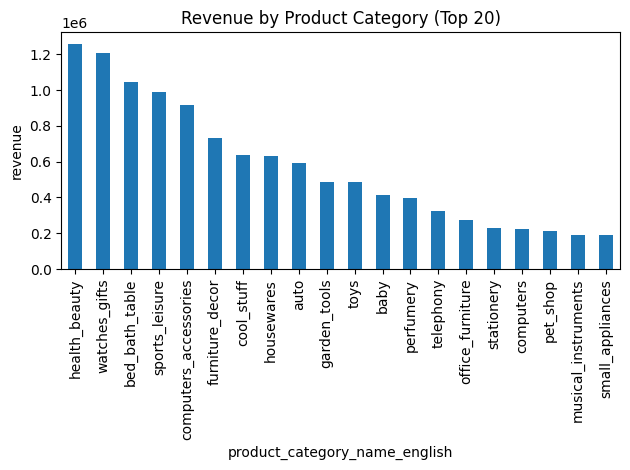

In [18]:
# 1) Revenue by Product Category
if fact_sales_path and dim_product_path and "product_category_name_english" in spark.read.format("delta").load(dim_product_path).columns:
    dim_product = spark.read.format("delta").load(dim_product_path)
    q1 = (fact_sales.join(dim_product.select("product_key","product_category_name_english"), "product_key")
          .groupBy("product_category_name_english")
          .agg(F.sum("revenue").alias("revenue"))
          .orderBy(F.desc("revenue")))
    pdf1 = q1.toPandas()
    plot_bar(pdf1.head(20), "product_category_name_english", "revenue", "Revenue by Product Category (Top 20)", rotation=90)
else:
    print("Skip plot 1: missing category translation / dim_product")


+------------+----------------+----+
|customer_key|lifetime_revenue|rank|
+------------+----------------+----+
|4311        |13440.0         |1   |
|45981       |7160.0          |2   |
|8589973441  |6735.0          |3   |
|8589982146  |6729.0          |4   |
|8589946925  |6499.0          |5   |
|1073        |5934.6          |6   |
|8589978081  |4799.0          |7   |
|8589941680  |4690.0          |8   |
|8589978315  |4599.9          |9   |
|8589946480  |4590.0          |10  |
+------------+----------------+----+



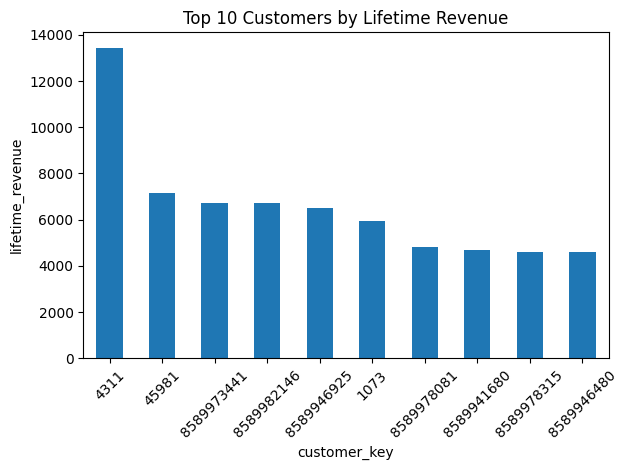

In [19]:
# 2) Top 10 Customers by Lifetime Revenue (window)
if fact_sales_path:
    w = Window.orderBy(F.desc("lifetime_revenue"))
    q2 = (fact_sales.groupBy("customer_key")
          .agg(F.sum("revenue").alias("lifetime_revenue"))
          .withColumn("rank", F.dense_rank().over(w))
          .filter("rank <= 10")
          .orderBy("rank"))
    q2.show(truncate=False)
    pdf2 = q2.toPandas()
    plot_bar(pdf2, "customer_key", "lifetime_revenue", "Top 10 Customers by Lifetime Revenue", rotation=45)


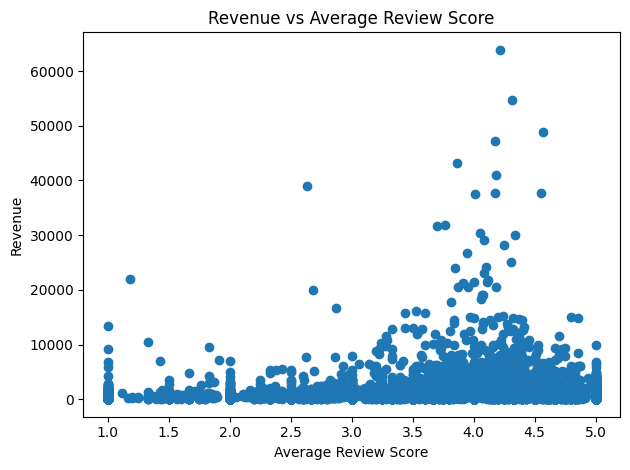

Correlation: -0.006663927273597673


In [20]:
# 3) Revenue vs Avg Review Score (correlation)
if fact_sales_path:
    q3 = (fact_sales.groupBy("product_key")
          .agg(F.sum("revenue").alias("revenue"), F.avg("review_score").alias("avg_review"))
          .dropna())
    pdf3 = q3.toPandas()
    plt.figure()
    plt.scatter(pdf3["avg_review"], pdf3["revenue"])
    plt.title("Revenue vs Average Review Score")
    plt.xlabel("Average Review Score")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()
    if len(pdf3) > 1:
        print("Correlation:", pdf3["avg_review"].corr(pdf3["revenue"]))


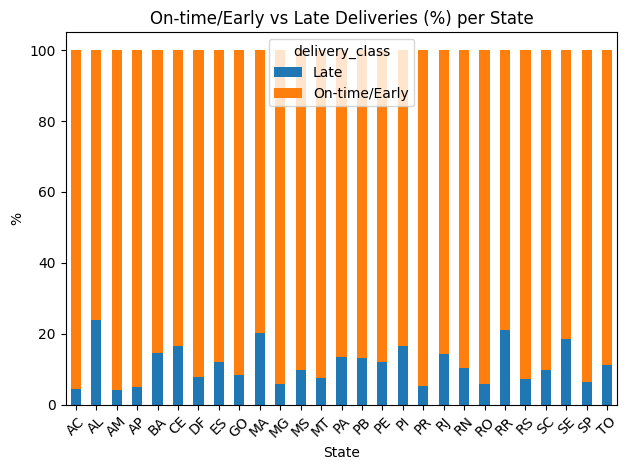

In [21]:
# 4) On-Time vs Late Deliveries (%) per State
if os.path.exists(f"{SILVER}/dim_customer_scd2") and fact_sales_path:
    dim_customer_cur = spark.read.format("delta").load(f"{SILVER}/dim_customer_scd2").filter("is_current=true")                         .select("customer_key", F.col("customer_state").alias("state"))
    q4_base = (fact_sales.join(dim_customer_cur, "customer_key")
               .withColumn("delivery_class",
                           F.when(F.col("delivery_delay_days") <= 0, F.lit("On-time/Early"))
                            .otherwise(F.lit("Late"))))
    q4 = q4_base.groupBy("state","delivery_class").agg(F.count("*").alias("cnt"))
    tot = q4_base.groupBy("state").agg(F.count("*").alias("total"))
    q4p = (q4.join(tot,"state")
           .withColumn("pct", F.col("cnt")/F.col("total")*100))
    pdf4 = q4p.toPandas().pivot(index="state", columns="delivery_class", values="pct").fillna(0).sort_index()
    pdf4.plot(kind="bar", stacked=True, title="On-time/Early vs Late Deliveries (%) per State")
    plt.xlabel("State"); plt.ylabel("%")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Skip plot 4: missing customer SCD2 or fact_sales")


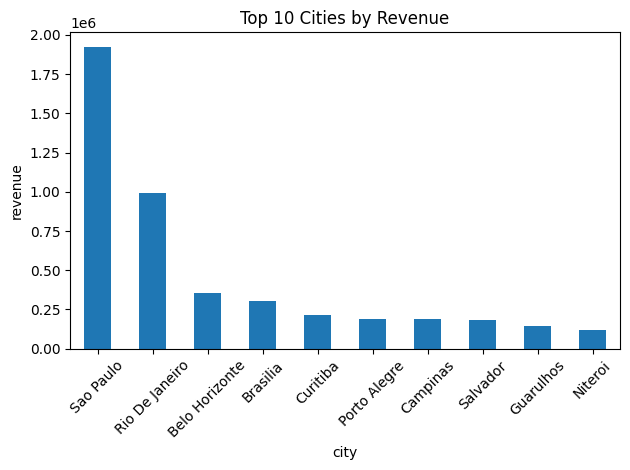

In [22]:
# 5) Top 10 Cities by Revenue
if os.path.exists(f"{SILVER}/dim_customer_scd2") and fact_sales_path:
    dim_customer_cur = spark.read.format("delta").load(f"{SILVER}/dim_customer_scd2").filter("is_current=true")                         .select("customer_key", F.col("customer_city").alias("city"))
    q5 = (fact_sales.join(dim_customer_cur, "customer_key")
          .groupBy("city")
          .agg(F.sum("revenue").alias("revenue"))
          .orderBy(F.desc("revenue"))
          .limit(10))
    pdf5 = q5.toPandas()
    plot_bar(pdf5, "city", "revenue", "Top 10 Cities by Revenue", rotation=45)
else:
    print("Skip plot 5: missing customer SCD2 or fact_sales")


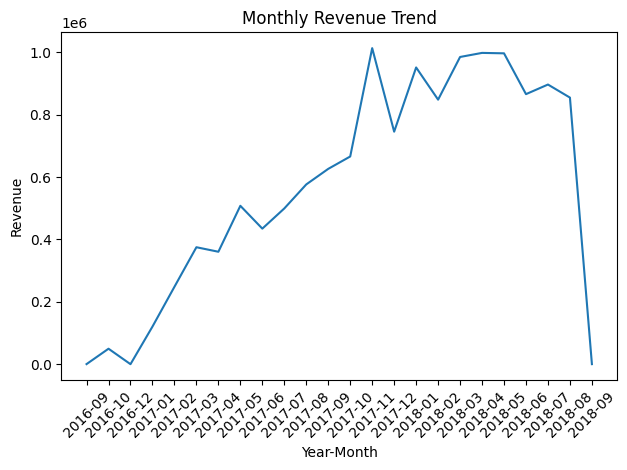

In [23]:
# 6) Monthly Revenue Trend
if fact_sales_path and dim_date_path:
    dim_date = spark.read.format("delta").load(dim_date_path)
    q6 = (fact_sales.join(dim_date.select("date_key","date"), "date_key")
          .withColumn("ym", F.date_format("date", "yyyy-MM"))
          .groupBy("ym")
          .agg(F.sum("revenue").alias("revenue"))
          .orderBy("ym"))
    pdf6 = q6.toPandas()
    plt.figure()
    plt.plot(pdf6["ym"], pdf6["revenue"])
    plt.title("Monthly Revenue Trend")
    plt.xlabel("Year-Month"); plt.ylabel("Revenue")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


CLV thresholds: 55.0 120.0


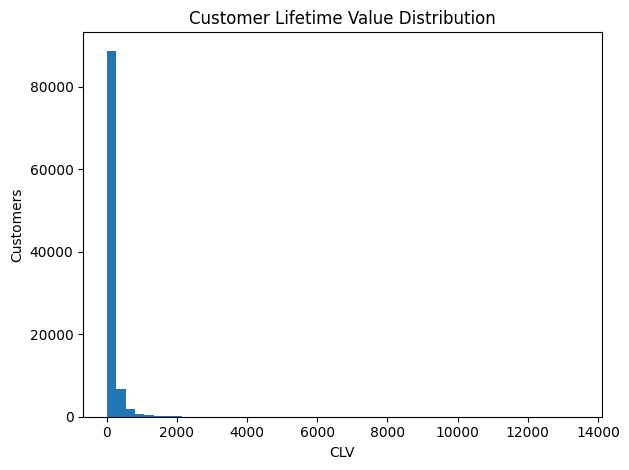

+-----------+-----+
|clv_segment|count|
+-----------+-----+
|       High|33228|
|        Low|31958|
|     Medium|33480|
+-----------+-----+



In [24]:
# 7) Customer Lifetime Value Distribution + Low/Medium/High (CASE-like logic)
if fact_sales_path:
    clv = (fact_sales.groupBy("customer_key")
           .agg(F.sum("revenue").alias("clv"),
                F.countDistinct("order_id").alias("orders"),
                F.avg("review_score").alias("avg_review")))

    # thresholds using approx quantiles
    qs = clv.approxQuantile("clv", [0.33, 0.66], 0.01)
    low_t, high_t = qs[0], qs[1]
    print("CLV thresholds:", low_t, high_t)

    clv_seg = (clv.withColumn(
                "clv_segment",
                F.when(F.col("clv") <= low_t, "Low")
                 .when(F.col("clv") <= high_t, "Medium")
                 .otherwise("High")
              ))

    pdf7 = clv_seg.select("clv").toPandas()
    plt.figure()
    plt.hist(pdf7["clv"], bins=50)
    plt.title("Customer Lifetime Value Distribution")
    plt.xlabel("CLV"); plt.ylabel("Customers")
    plt.tight_layout()
    plt.show()

    clv_seg.groupBy("clv_segment").count().show()


## 8) Advanced: Customer Segmentation + Delivery KPI
Segmenten (voorbeeld): VIP / Loyal / At Risk / One-time buyers.
Je kan de drempels aanpassen en motiveren.

In [25]:
if fact_sales_path:
    fact = spark.read.format("delta").load(fact_sales_path)

    fact_kpi = (fact
        .withColumn("delivery_perf",
            F.when(F.col("delivery_delay_days") < 0, "Early")
             .when(F.col("delivery_delay_days") == 0, "On-time")
             .otherwise("Late"))
    )

    late_ratio = (fact_kpi
        .groupBy("customer_key")
        .agg(F.avg(F.when(F.col("delivery_perf")=="Late", 1).otherwise(0)).alias("late_ratio"))
    )

    clv = (fact.groupBy("customer_key")
           .agg(F.sum("revenue").alias("clv"),
                F.countDistinct("order_id").alias("orders"),
                F.avg("review_score").alias("avg_review"))
           .join(late_ratio, "customer_key", "left")
           .fillna({"late_ratio":0.0}))

    p90 = clv.approxQuantile("clv",[0.90],0.01)[0]

    seg = (clv.withColumn(
            "segment",
            F.when((F.col("clv") >= p90) & (F.col("avg_review") >= 4), "VIP")
             .when(F.col("orders") == 1, "One-time buyers")
             .when((F.col("late_ratio") > 0.30) | (F.col("avg_review") <= 2.5), "At Risk")
             .otherwise("Loyal")
         ))

    seg.groupBy("segment").count().orderBy(F.desc("count")).show()

    # Extra window: cumulative revenue by month
    if dim_date_path:
        dim_date = spark.read.format("delta").load(dim_date_path)
        monthly = (fact.join(dim_date.select("date_key","date"), "date_key")
                   .withColumn("ym", F.date_format("date","yyyy-MM"))
                   .groupBy("ym")
                   .agg(F.sum("revenue").alias("revenue"))
                   .orderBy("ym"))
        w = Window.orderBy("ym").rowsBetween(Window.unboundedPreceding, Window.currentRow)
        monthly = monthly.withColumn("cum_revenue", F.sum("revenue").over(w))
        monthly.show(24, truncate=False)


+---------------+-----+
|        segment|count|
+---------------+-----+
|One-time buyers|91268|
|            VIP| 7398|
+---------------+-----+

+-------+------------------+--------------------+
|ym     |revenue           |cum_revenue         |
+-------+------------------+--------------------+
|2016-09|267.36            |267.36              |
|2016-10|49594.36000000009 |49861.72000000009   |
|2016-12|10.9              |49872.62000000009   |
|2017-01|120534.49000000037|170407.11000000045  |
|2017-02|248132.71999999922|418539.82999999967  |
|2017-03|374988.99999999534|793528.829999995    |
|2017-04|360489.0199999958 |1154017.8499999908  |
|2017-05|507830.3299999901 |1661848.1799999808  |
|2017-06|434633.4199999933 |2096481.599999974   |
|2017-07|499296.2599999901 |2595777.859999964   |
|2017-08|576348.2199999935 |3172126.0799999572  |
|2017-09|626239.3599999965 |3798365.439999954   |
|2017-10|665898.1599999984 |4464263.599999952   |
|2017-11|1013306.4800000165|5477570.079999968   |
|2017